# Notebook 14 — Train Soil-to-Leaf Nutrient Model

Trains a MultiOutput ExtraTreesRegressor to predict Leaf N, P, K from Soil N, P, K and engineered ratios.

In [ ]:
import os
import sys
import subprocess

def install_if_missing(module_name, package_name=None):
    if package_name is None:
        package_name = module_name
    try:
        __import__(module_name)
    except ImportError:
        print(f"Installing {package_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])

install_if_missing('pandas')
install_if_missing('numpy')
install_if_missing('sklearn', 'scikit-learn')
install_if_missing('joblib')
install_if_missing('matplotlib')

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure project root is in the path
current_dir = Path(os.getcwd())
if current_dir.name == 'notebooks':
    sys.path.append(str(current_dir.parent))
else:
    sys.path.append(str(current_dir))
    
import config

PROCESSED_DIR = config.PROCESSED_DIR
MODELS_DIR = config.MODELS_DIR
FIGURES_DIR = config.BASE_DIR / 'figures'


## 1. Load Processed Data

In [15]:
df = pd.read_csv(PROCESSED_DIR / 'soil_leaf_processed.csv')
print(f"Loaded dataset with {len(df)} rows.")
print(df.head())


Loaded dataset with 5815 rows.
   tree_id  soil_n   soil_p    soil_k  leaf_n  leaf_p    leaf_k  np_ratio  \
0       30  0.0159  0.34302  0.062942  1.1544    0.79  0.526852  0.046353   
1       49  0.0335  0.15298  0.065793  1.5392    0.18  0.486641  0.218981   
2       54  0.0182  0.15068  0.086126  0.8658    0.18  0.490941  0.120785   
3       64  0.0218  0.11085  0.111790  2.4293    0.81  0.548500  0.196660   
4       91  0.0124  0.11184  0.140943  1.4430    0.24  0.529178  0.110872   

   nk_ratio  pk_ratio   npk_sum  
0  0.252610  5.449693  0.421862  
1  0.509165  2.325136  0.252273  
2  0.211316  1.749509  0.255006  
3  0.195007  0.991583  0.244440  
4  0.087978  0.793507  0.265183  


## 2. Train-Test Split
Features: `soil_n`, `soil_p`, `soil_k`, `np_ratio`, `nk_ratio`, `pk_ratio`, `npk_sum`
Targets: `leaf_n`, `leaf_p`, `leaf_k`

In [16]:
features = ['soil_n', 'soil_p', 'soil_k', 'np_ratio', 'nk_ratio', 'pk_ratio', 'npk_sum']
targets = ['leaf_n', 'leaf_p', 'leaf_k']

X = df[features]
y = df[targets]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 4652, Test size: 1163


## 3. Train MultiOutput ExtraTreesRegressor

In [17]:
base_estimator = ExtraTreesRegressor(n_estimators=300, max_depth=20, random_state=42, n_jobs=-1)
model = MultiOutputRegressor(base_estimator)
model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 4. Evaluation and Plotting

[leaf_n] MAE: 0.1244, RMSE: 0.2019, R2: 0.5622
[leaf_p] MAE: 0.0559, RMSE: 0.0875, R2: 0.6063
[leaf_k] MAE: 0.0111, RMSE: 0.0245, R2: 0.5234
Saved evaluation plot to C:\Users\yoshi\Desktop\PP2\V1\backend\Coconut_Yield_Prediction\figures\soil_leaf_prediction_results.png


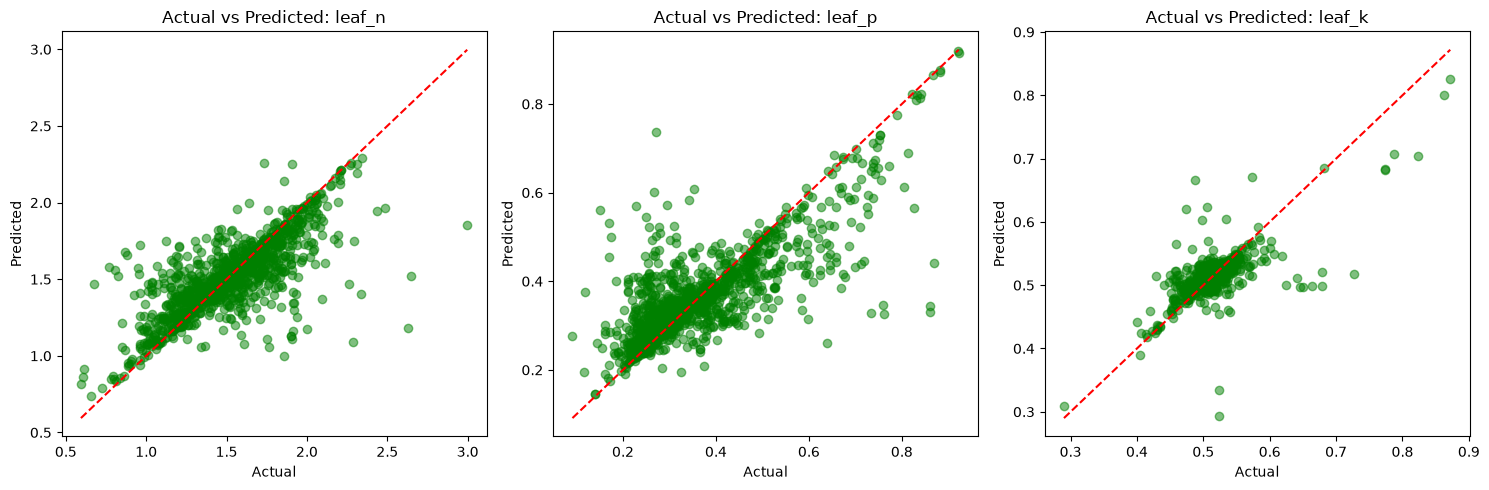

In [18]:
y_pred = model.predict(X_test)
y_pred_df = pd.DataFrame(y_pred, columns=targets)

for i, target in enumerate(targets):
    mae = mean_absolute_error(y_test[target], y_pred_df[target])
    rmse = np.sqrt(mean_squared_error(y_test[target], y_pred_df[target]))
    r2 = r2_score(y_test[target], y_pred_df[target])
    print(f"[{target}] MAE: {mae:.4f}, RMSE: {rmse:.4f}, R2: {r2:.4f}")

# Create scatter plots for actual vs predicted, wrapped in try-except in case matplotlib is broken
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for i, target in enumerate(targets):
        axes[i].scatter(y_test[target], y_pred_df[target], alpha=0.5, color='green')
        axes[i].plot([y_test[target].min(), y_test[target].max()], 
                     [y_test[target].min(), y_test[target].max()], 'r--')
        axes[i].set_title(f'Actual vs Predicted: {target}')
        axes[i].set_xlabel('Actual')
        axes[i].set_ylabel('Predicted')
    plt.tight_layout()
    fig_path = FIGURES_DIR / 'soil_leaf_prediction_results.png'
    plt.savefig(fig_path)
    print(f"Saved evaluation plot to {fig_path}")
except ImportError as e:
    print("Matplotlib is not working properly in this environment, skipping plot generation.")
    print("Error details:", str(e))

## 5. Save the Model

In [19]:
model_path = MODELS_DIR / 'soil_leaf_model.joblib'
joblib.dump(model, model_path)
print(f"Saved trained model to {model_path}")

Saved trained model to C:\Users\yoshi\Desktop\PP2\V1\backend\Coconut_Yield_Prediction\models\soil_leaf_model.joblib
